In [9]:
import os
#import argparse
#parser=argparse.ArgumentParser(description='trim video into short piece')
#parser.add_argument('-i','--input_path',help='path to the video as a string: eg. C:/Users/../, apostrophe not shown',type=str,default='Z:/DATA/experiment_trackball_Optomotor')
#parser.add_argument('-n','--exp_name',help='the stimulus name of the experiment: eg. xxx, apostrophe not shown',type=str,default='gratings')
#parser.add_argument('-d','--exp_date',help='the date of the experiment',type=list,default=['220712','220714'])
#args= parser.parse_args()
#def create_data_list(input_path, exp_name, exp_date):
data_list=[]
input_path = 'Z:/DATA/experiment_trackball_Optomotor'
dataset=os.listdir(input_path)
exp_date= ['221124']
exp_name='splitcohdens'
for locust in dataset:
    locust_directory=input_path + '/' + locust
    file_list = os.listdir(locust_directory)
    for thisDate in file_list:
        if thisDate in exp_date:
            experiment_directory=locust_directory + '/' + thisDate
            experiment_list=os.listdir(experiment_directory)
            for thisExperiment in experiment_list:
                if thisExperiment in exp_name:
                    data_list.append(experiment_directory + '/' + exp_name)
#    return data_list

#if __name__ == '__main__':
#    create_data_list(args.input_path,args.exp_name,args.exp_date)

In [3]:
data_list=data_list[1::]

In [47]:
exp_name='splitcohdens'

In [10]:
data_list

['Z:/DATA/experiment_trackball_Optomotor/L22219/221124/splitcohdens',
 'Z:/DATA/experiment_trackball_Optomotor/L22220/221124/splitcohdens',
 'Z:/DATA/experiment_trackball_Optomotor/L22221/221124/splitcohdens',
 'Z:/DATA/experiment_trackball_Optomotor/L22222/221124/splitcohdens',
 'Z:/DATA/experiment_trackball_Optomotor/L22223/221124/splitcohdens']

In [87]:
##The meta information of the stimulus is now included in each cell when the stimulus is delivered
##They are saved as stim_variable object.
##For gratings: it only includs temporal frequency at the moment 2022 sep 6th
##For sweeploom: it includs the initial and ending size; initial and ending position, by this order 
##For sweeploom: it includs stimid, size, Colour1, numDots1, Contrast1, VelX1, Coherence1 by this order 
import os, fnmatch
import pandas as pd
import numpy as np
import re
import math

overwrite_file=False
save_file=True
csv_pattern='trial_*.csv'
dat_pattern='*.dat'    
track_ball_radius=4
frame_rate=144
stim_duration = 120 # in sec
grey_duration = 0
for thisDir in data_list:
    animal_name =thisDir.split('/')[3]
    # list up the files in the dir
    file = os.listdir(thisDir)
    # look for files that matches the pattern
    csv_file= fnmatch.filter(file, csv_pattern)  
    dat_file= fnmatch.filter(file, dat_pattern)
    csv_file_directory= os.path.join(thisDir + '/' ,csv_file[0])
    dat_file_directory= os.path.join(thisDir + '/' ,dat_file[0])
    stim_info = pd.read_csv(csv_file_directory)
    
    stim_info=stim_info.dropna(0)
    stim_info=stim_info.reset_index()
    stim_info.Timestamp=stim_info.Timestamp.astype('int')
    
    if stim_info.size == 0:
        print(thisDir + ' has no stim_info: skipped')
        continue
        
#     if exp_name == 'splitscreen':
#         stim_info = stim_info.iloc[::2,:]
#         stim_info=stim_info.reset_index()
    stim_variable=[]
    stimulus_timestamp=[]
    if exp_name == 'gratings':
        for row in range(0, len(stim_info)):
        #delete the bracket in current speed and save it as integer in new list
            stim_variable.append(int(stim_info.loc[row, 'Frame'].replace('(', '')))
        # combine the last two values into the timestamp (were divided into 2 columns cause german computer
        # used comma as decimal seperator and save timestamp as float in new file
            if isinstance(stim_info.loc[row, 'Value'], float):
                timestamp = stim_info.loc[row, 'Timestamp']
            else:
                timestamp = str(stim_info.loc[row, 'Timestamp']) + '.' + stim_info.loc[row, 'Value']
            stimulus_timestamp.append(float(timestamp.replace(')', '')))
        stim_variable=np.array(stim_variable).reshape((len(stim_info), -1))

    elif exp_name == 'sweeploom':
        for row in range(0, len(stim_info)):
            stim_variable.append(int(stim_info.iloc[row,2].split("=",1)[1]))
            stim_variable.append(int(stim_info.iloc[row,3].split("=",1)[1]))
            stim_variable.append(int(stim_info.iloc[row,4].split("=",1)[1]))
            stim_variable.append(int(re.split(r'=|}',stim_info.iloc[row,5])[1]))
            if isinstance(stim_info.loc[row, 'Value'], float):
                timestamp = stim_info.loc[row, 'Timestamp']
            else:
                timestamp = str(stim_info.loc[row, 'Timestamp']) + '.' + stim_info.loc[row, 'Value']
            stimulus_timestamp.append(float(timestamp.replace(')', '')))
        stim_variable=np.array(stim_variable).reshape((len(stim_info), -1))
        #some bugs in the bonsai workflow. Needs to remove the first timestamp and the last row of stim variable here
        stimulus_timestamp.pop(0)
        stim_variable=np.delete(stim_variable, -1, axis=0)
    elif exp_name == 'dots' or exp_name == 'densities' :
        for row in range(0, len(stim_info)):
            stim_variable.append(int(stim_info.iloc[row,2].split("=",1)[1]))
            stim_variable.append(int(stim_info.iloc[row,4].split("=",1)[1]))
            stim_variable.append(int(stim_info.iloc[row,5].split("=",1)[1]))
            stim_variable.append(int(stim_info.iloc[row,7].split("=",1)[1]))
            stim_variable.append(int(stim_info.iloc[row,11].split("=",1)[1]))
            stim_variable.append(int(stim_info.iloc[row,13].split("=",1)[1]))
            stim_variable.append(int(stim_info.iloc[row,17].split("=",1)[1]))
            if isinstance(stim_info.loc[row, 'Value'], float):
                timestamp = stim_info.loc[row, 'Timestamp']
            else:
                timestamp = str(stim_info.loc[row, 'Timestamp']) + '.' + stim_info.loc[row, 'Value']
            stimulus_timestamp.append(float(timestamp.replace(')', '')))
        stim_variable=np.array(stim_variable).reshape((len(stim_info), -1))
        
    elif exp_name=='splitscreen':
        for row in range(0, len(stim_info)):
            stim_variable.append(int(stim_info.iloc[row,8].split("=",1)[1]))
            stim_variable.append(int(stim_info.iloc[row,9].split("=",1)[1]))

            if isinstance(stim_info.loc[row, 'Value'], float):
                timestamp = stim_info.loc[row, 'Timestamp']
            else:
                timestamp = str(stim_info.loc[row, 'Timestamp']) + '.' + stim_info.loc[row, 'Value']
            stimulus_timestamp.append(float(timestamp.replace(')', '')))
        stim_variable=np.array(stim_variable).reshape((len(stim_info), -1))
        
    elif exp_name== 'splitforward'or exp_name=='testlinks' or exp_name == 'testrechts':
        for row in range(0, len(stim_info)):
            stim_variable.append(int(stim_info.iloc[row,7].split("=",1)[1]))
            stim_variable.append(int(stim_info.iloc[row,8].split("=",1)[1]))
            
            if isinstance(stim_info.loc[row, 'Value'], float):
                timestamp = stim_info.loc[row, 'Timestamp']
            else:
                timestamp = str(stim_info.loc[row, 'Timestamp']) + '.' + stim_info.loc[row, 'Value']
            stimulus_timestamp.append(float(timestamp.replace(')', '')))
        stim_variable=np.array(stim_variable).reshape((len(stim_info), -1))  
        
    elif exp_name== 'splitlongfront':
        for row in range(0, len(stim_info)):
            stim_variable.append(int(stim_info.iloc[row,7].split("=",1)[1]))
            stim_variable.append(int(stim_info.iloc[row,8].split("=",1)[1]))
            stim_variable.append(int(stim_info.iloc[row,13].split("=",1)[1]))
            stim_variable.append(int(stim_info.iloc[row,14].split("=",1)[1]))
            
            
            if isinstance(stim_info.loc[row, 'Value'], float):
                timestamp = stim_info.loc[row, 'Timestamp']
            else:
                timestamp = str(stim_info.loc[row, 'Timestamp']) + '.' + stim_info.loc[row, 'Value']
            stimulus_timestamp.append(float(timestamp.replace(')', '')))
        stim_variable=np.array(stim_variable).reshape((len(stim_info), -1))
        
    elif exp_name== 'splitcohdens':
        for row in range(0, len(stim_info)):
            stim_variable.append(int(stim_info.iloc[row,7].split("=",1)[1]))
            stim_variable.append(int(stim_info.iloc[row,8].split("=",1)[1]))
            stim_variable.append(int(stim_info.iloc[row,13].split("=",1)[1]))
            stim_variable.append(int(stim_info.iloc[row,14].split("=",1)[1]))
            stim_variable.append(int(stim_info.iloc[row,17].split("=",1)[1]))
            stim_variable.append(int(stim_info.iloc[row,18].split("=",1)[1].replace('}', '')))
            
            if isinstance(stim_info.loc[row, 'Value'], float):
                timestamp = stim_info.loc[row, 'Timestamp']
            else:
                timestamp = str(stim_info.loc[row, 'Timestamp']) + '.' + stim_info.loc[row, 'Value']
            stimulus_timestamp.append(float(timestamp.replace(')', '')))
        stim_variable=np.array(stim_variable).reshape((len(stim_info), -1))
        
    elif exp_name=='splitcoh':
        for row in range(0, len(stim_info)):
            stim_variable.append(int(stim_info.iloc[row,17].split("=",1)[1]))
            stim_variable.append(int(stim_info.iloc[row,18].split("=",1)[1].replace('}', '')))

            if isinstance(stim_info.loc[row, 'Value'], float):
                timestamp = stim_info.loc[row, 'Timestamp']
            else:
                timestamp = str(stim_info.loc[row, 'Timestamp']) + '.' + stim_info.loc[row, 'Value']
            stimulus_timestamp.append(float(timestamp.replace(')', '')))
        stim_variable=np.array(stim_variable).reshape((len(stim_info), -1))
    else:
        warnings.warn('stimulus paradigm can not be recognised')

    ## load dat file
    ## fictrac title is here 'frame counter', 'delta rotation vector cam x', 'delta rotation vector cam y', \
    ##'delta rotation vector cam z', 'delta rotation error score', 'delta rotation vector lab x', \
    ##'delta rotation vector lab y', 'delta rotation vector lab z', 'absolute rotation vector cam x',\
    ##'absolute rotation vector cam y', 'absolute rotation vector cam z', \
    ##'absolute rotation vector lab x', 'absolute rotation vector lab y', \
    ##'absolute rotation vector lab z', 'intergrated x position','intergrated y position', \
    ##'intergrated animal heading', 'animal movement direction', 'animal movement speed', \
    ##'intergrated forward motion','intergrated side motion', 'timestamp', 'sequence counter','delta timestamp', 'alt. timestamp']

    ## load dat file
    raw_data = pd.read_table(dat_file_directory, sep="\s+")

    ## drop some column
    raw_data.drop(raw_data.columns[[0,1,2,3,4,8,9,10,16,17,18,19,20,21,22,23]], axis=1, inplace=True)
    raw_data.columns=['delta rotation vector lab x', 'delta rotation vector lab y', 'delta rotation vector lab z',                       'absolute rotation vector lab x', 'absolute rotation vector lab y', 'absolute rotation vector lab z',                       'intergrated x position','intergrated y position', 'timestamp']
    ## cleaning , and change the data from object to float
    raw_data.iloc[:, :]=raw_data.iloc[:, :].replace({',': ''}, regex= True)
    for ind in range(0, raw_data.shape[1]):
        raw_data.iloc[:, ind]=pd.to_numeric(raw_data.iloc[:, ind]).astype('float32')

    ## adjust the unit of the x, y position
    raw_data.iloc[:, 6]=raw_data.iloc[:, 6]*track_ball_radius
    raw_data.iloc[:, 7]=raw_data.iloc[:, 7]*track_ball_radius
    ## adjust the unit of the z vector based on the target frame rate of fictrac
    raw_data.iloc[:, 2]=raw_data.iloc[:, 2]*frame_rate

    # apply filter to the raw trace
    #curr_data.loc[:, ['x_pos']] = scipy.signal.savgol_filter(curr_data.loc[:, ['x_pos']], 99, 3, axis=0)
    #curr_data.loc[:, ['y_pos']] = scipy.signal.savgol_filter(curr_data.loc[:, ['y_pos']], 99, 3, axis=0)

    # compare the timestamp between event file and dat file
    data_timestamp=raw_data.loc[:, 'timestamp']
    stimulus_timestamp_b=np.tile(stimulus_timestamp,(len(data_timestamp),1))
    data_timestamp_b=np.tile(data_timestamp,(len(stimulus_timestamp),1))
    timestamp_diff= data_timestamp_b > np.transpose(stimulus_timestamp_b)
    stim_onset= np.where(np.roll(timestamp_diff,1,axis=1)!=timestamp_diff)[1][1::2]
    
    if stim_onset.size == 0:
        print(thisDir + 'timestamp matching issue: skipped')
        continue
        
    ### add new column here to store event info
#         raw_data['frame_rate']=frame_rate
#         if isinstance(frame_rate, int):
#             raw_data['frame_rate']=raw_data['frame_rate'].astype('int16')  
#         elif isinstance(frame_rate, int):
#             raw_data['frame_rate']=raw_data['frame_rate'].astype('float16')

    raw_data['stim_duration']=stim_duration
    raw_data['stim_duration']=raw_data['stim_duration'].astype('int8')        
    raw_data['grey_duration']=grey_duration
    if isinstance(grey_duration, int):
        raw_data['grey_duration']=raw_data['grey_duration'].astype('int8') 

    raw_data['stim_onset']=False
    stim_onset = stim_onset + np.ones(np.shape(stim_onset),dtype=int)*int(stim_duration/2)*int(frame_rate)
    raw_data.loc[stim_onset, 'stim_onset']=True
    raw_data['stim_variable']=object
    for ind in range(0, len(stimulus_timestamp)):
        ## use at not loc as the data input is object not int
        raw_data.at[stim_onset[ind], 'stim_variable']=stim_variable[ind,:]

    ### save the curated_database
    if save_file==True:
        database_name='database_curated.pickle'
        database_directory= os.path.join(thisDir,database_name)
        if (overwrite_file ==False) and (os.path.isfile == True):
            continue
        else:
            raw_data.to_pickle(database_directory)

C:\Users\excid\AppData\Local\Temp/ipykernel_5224/3221822275.py:31: FutureWarning: In a future version of pandas all arguments of DataFrame.dropna will be keyword-only
  stim_info=stim_info.dropna(0)


Z:/DATA/experiment_trackball_Optomotor/L22219/221124/splitcohdens
percent of events under treshold
22.22222222222222


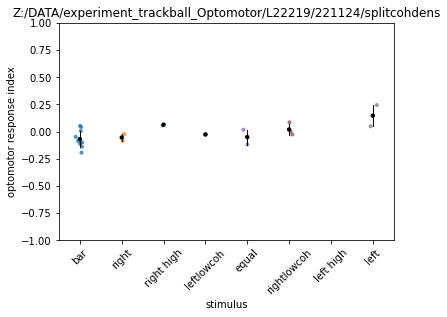

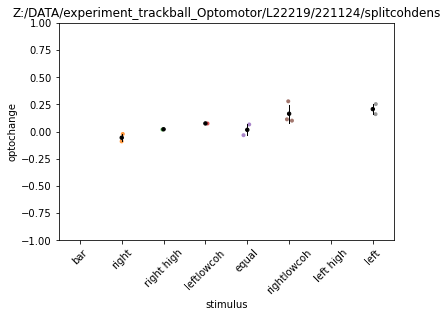

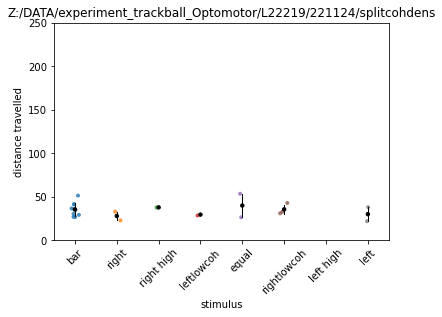

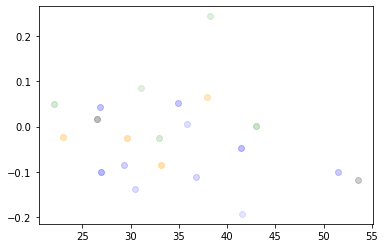

Z:/DATA/experiment_trackball_Optomotor/L22220/221124/splitcohdens
percent of events under treshold
0.0


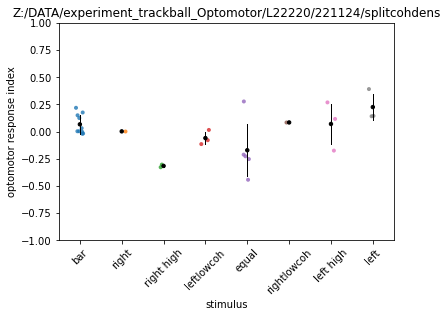

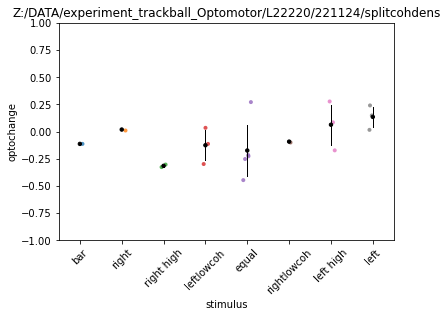

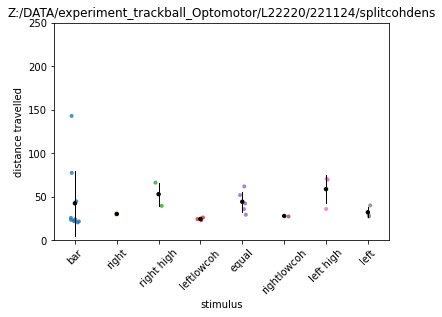

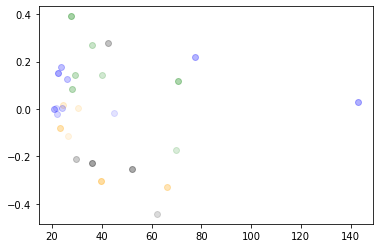

Z:/DATA/experiment_trackball_Optomotor/L22221/221124/splitcohdens
percent of events under treshold
5.555555555555555


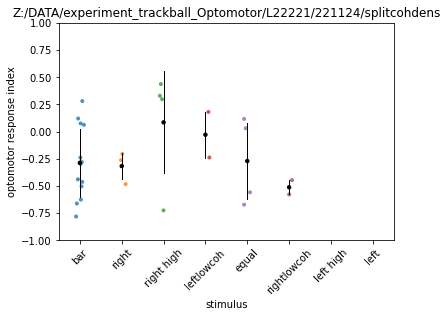

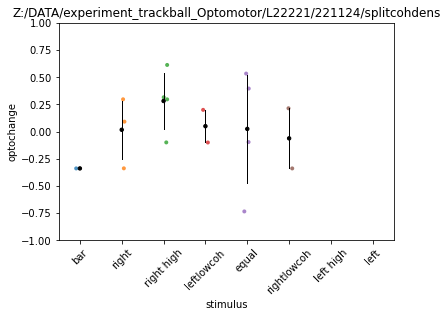

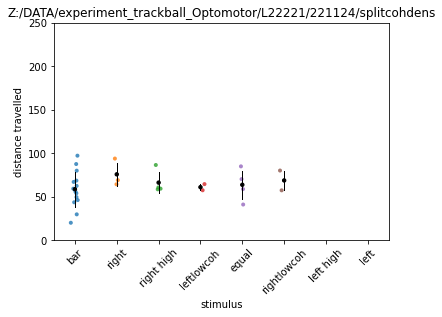

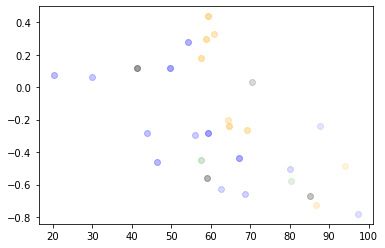

Z:/DATA/experiment_trackball_Optomotor/L22222/221124/splitcohdens
percent of events under treshold
0.0


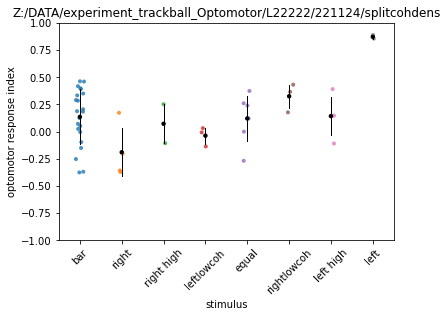

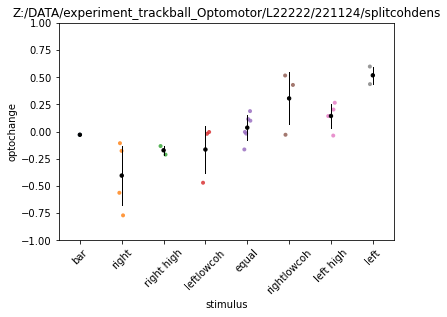

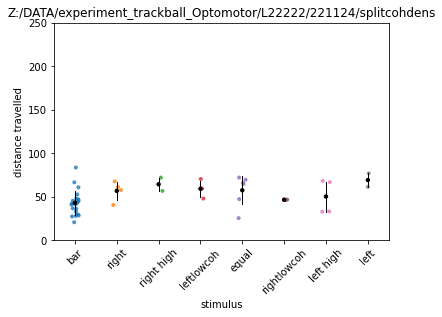

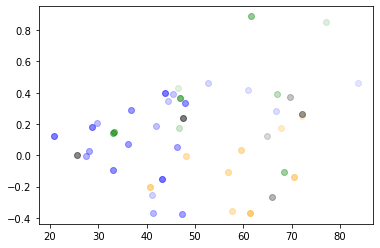

Z:/DATA/experiment_trackball_Optomotor/L22223/221124/splitcohdens
percent of events under treshold
0.0


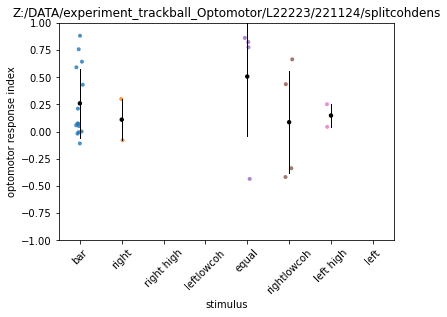

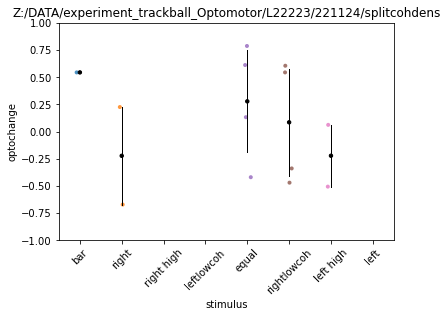

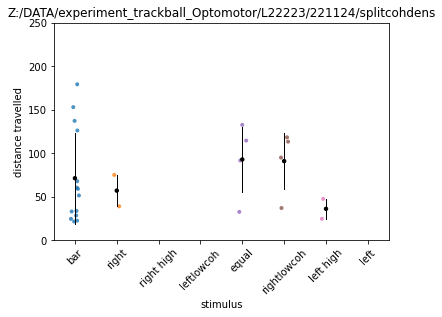

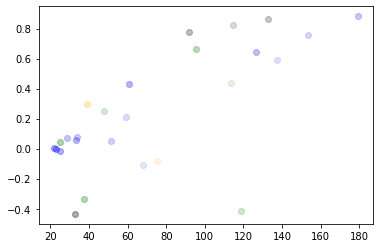

In [11]:
import os, fnmatch
import pandas as pd
import numpy as np
from scipy.signal import savgol_filter
import matplotlib.pyplot as plt
import seaborn as sns


savefigure = False
gettraj = False

database_pattern='*.pickle'
frame_rate=144
sg_filering= True
averages = pd.DataFrame(np.zeros((1000,2)), columns = ['stimulus', 'optomotor response index'])
averages[:] = np.nan
c=0
for thisDir in data_list:
    animal_name =thisDir.split('/')[3]
    file = os.listdir(thisDir)
    file_name= fnmatch.filter(file, database_pattern)
    if file_name==[]:
        print('skipped ' + thisDir)
        continue
    database= os.path.join(thisDir+'/',file_name[0])
    df=pd.read_pickle(database)
    
    stim_duration=60
    grey_duration=60
    analysis_window=frame_rate*(stim_duration+grey_duration)
    df.loc[:,'grey_onset'] =False

    if sg_filering == True:
        df.loc[:, ['intergrated x position']] = savgol_filter(df.loc[:, ['intergrated x position']], 19, 3, axis=0)
        df.loc[:, ['intergrated y position']] = savgol_filter(df.loc[:, ['intergrated y position']], 19, 3, axis=0)

    stim_onset=np.where(df.loc[:,'stim_onset']==True)
    stim_onset = stim_onset + np.zeros(np.shape(stim_onset),dtype=int)
    grey_onset=stim_onset-np.ones(np.shape(stim_onset),dtype=int)*grey_duration*frame_rate
    stim_offset=stim_onset+np.ones(np.shape(stim_onset),dtype=int)*stim_duration*frame_rate
#     stim_onset=np.where(df.loc[:,'stim_onset']==True)
    
#     grey_onset=stim_onset-np.zeros(np.shape(stim_onset),dtype=int)
#     stim_onset = stim_onset + np.ones(np.shape(stim_onset),dtype=int)*(stim_duration/2)*frame_rate
    
#     stim_offset=stim_onset+np.ones(np.shape(stim_onset),dtype=int)*(stim_duration/2-1)*frame_rate
#     df.stim_onset = False
    
   
    
    for ind in range(0,stim_onset.shape[1]):
        #data_of_interest[ind,:]=df.loc[grey_onset[0,ind]+1:stim_offset[0,ind],'delta rotation vector lab z']
        
        #df.loc[grey_onset[0,ind]:stim_offset[0,ind],'stim_variable'] = df.at[grey_onset[0,ind],'stim_variable']+ np.zeros([len(df.loc[grey_onset[0,ind]:stim_offset[0,ind],:]), 1])
        #df.loc[stim_onset[0,ind],'stim_onset']=True
        df.loc[grey_onset[0,ind], 'grey_onset']=True
        
        df.loc[stim_onset[0,ind]:stim_offset[0,ind],'event_num'] = int(ind+1)
        df.loc[grey_onset[0,ind]:(stim_onset[0,ind])-1, 'stimulus']= 'bar'
        df.loc[grey_onset[0,ind]:(stim_onset[0,ind])-1, 'event_num']= 'NaN'

        ev_dat = df.loc[stim_onset[0,ind]:stim_offset[0,ind]]
        bar_dat = df.loc[grey_onset[0,ind]:stim_onset[0,ind]-1]
        #ev_dat =ev_dat.loc[abs(df.anglechange)<5,:]
        ev_dat = ev_dat.reset_index()
        df.loc[stim_onset[0,ind]:stim_offset[0,ind],'distance travelled'] = distance_travelled(ev_dat)
        df.loc[stim_onset[0,ind]:stim_offset[0,ind],'optomotor response index'] = optomotor_response_idx(ev_dat.loc[: ,'delta rotation vector lab z'])
        
        
        #ev_dat =ev_dat.loc[abs(df.anglechange)<5,:]
        bar_dat = bar_dat.reset_index()
        df.loc[grey_onset[0,ind]:(stim_onset[0,ind])-1,'distance travelled'] = distance_travelled(bar_dat)
        df.loc[grey_onset[0,ind]:(stim_onset[0,ind])-1,'optomotor response index'] = optomotor_response_idx(bar_dat.loc[: ,'delta rotation vector lab z'])
        
        df.loc[stim_onset[0,ind]:stim_offset[0,ind],'optochange'] = df.loc[stim_onset[0,ind],'optomotor response index']-df.loc[grey_onset[0,ind],'optomotor response index']
        
        if gettraj == True:
            plt.plot(ev_dat.loc[:, 'intergrated x position'], ev_dat.loc[:,'intergrated y position'], 'red', label='stim: ' + str(np.round(df.loc[stim_onset[0,ind],'optomotor response index'], decimals= 3)))
            plt.plot(bar_dat.loc[:, 'intergrated x position'], bar_dat.loc[:,'intergrated y position'], 'blue', label='bar: ' + str(np.round(df.loc[grey_onset[0,ind],'optomotor response index'], decimals=3)))
            title = animal_name + '; ' + 'event '+ str(ind +1)+ '; '+ str(ev_dat.stim_variable[0][1]) + '-' + str(ev_dat.stim_variable[0][0])
            if (ev_dat.stim_variable[0][0]==256) & (ev_dat.stim_variable[0][1]==256) & (ev_dat.stim_variable[0][2]==ev_dat.stim_variable[0][3]):
                if ev_dat.stim_variable[0][2]<0:
                    title= title + ' right'
                elif ev_dat.stim_variable[0][2]>0:
                    title = title + ' left'
           
            if exp_name=='splitcohdens':
                    if (ev_dat.stim_variable[0][0]==256) & (ev_dat.stim_variable[0][1]==256) & (ev_dat.stim_variable[0][3]!=ev_dat.stim_variable[0][4]):
                        if ev_dat.stim_variable[0][4]==20:
                            title= title + ' rightlowcoh'
                        elif ev_dat.stim_variable[0][5]==20:
                            title = title + ' leftlowcoh'
            plt.title(title)
            plt.legend(loc='upper right')


            if savefigure==True:
                figure_name= 'traj' + str(ind+1) + '.svg'
                directoryfig=os.path.join(thisDir,figure_name)
                plt.savefig(directoryfig)

            plt.show()
        
    df.event_num=df.event_num.astype('category')
    x = df.loc[df.stim_onset==True, :].reset_index()
    
    for i in range(0,len(x)):
        if exp_name == 'densities':
            cond=x.stim_variable[i][3]*(x.stim_variable[i][5]/abs(x.stim_variable[i][5]))
            df.loc[df.event_num == x.loc[i, 'event_num'],'stimulus'] = cond

        elif exp_name =='splitscreen':
            conditions = [(x.stim_variable[i][0]==256) & (x.stim_variable[i][1]==256),
                          (x.stim_variable[i][0]==256) & (x.stim_variable[i][1] ==64),
                          (x.stim_variable[i][0]==256) & (x.stim_variable[i][1]==4096),
                          (x.stim_variable[i][0]==64) & (x.stim_variable[i][1] == 256),
                          (x.stim_variable[i][0] == 4096) & (x.stim_variable[i][1] == 256)]
        
            choices = ['equal', 'right low', 'right high', 'left low', 'left high']
            df.loc[df.event_num == x.loc[i, 'event_num'],'stimulus']=np.select(conditions, choices)
        elif exp_name =='splitforward'or exp_name=='testlinks' or exp_name == 'testrechts':
            conditions = [(x.stim_variable[i][0]==256) & (x.stim_variable[i][1]==256),
                          (x.stim_variable[i][0]==256) & (x.stim_variable[i][1] ==64),
                          (x.stim_variable[i][0]==256) & (x.stim_variable[i][1]==4096),
                          (x.stim_variable[i][0]==64) & (x.stim_variable[i][1] == 256),
                          (x.stim_variable[i][0] == 4096) & (x.stim_variable[i][1] == 256)]
        
            choices = ['equal', 'left low', 'left high', 'right low', 'right high']
            df.loc[df.event_num == x.loc[i, 'event_num'],'stimulus']=np.select(conditions, choices) 
            
        elif exp_name =='splitcohdens':
            conditions = [(x.stim_variable[i][0]==256) & (x.stim_variable[i][1]==256) & (x.stim_variable[i][2]==-64) & (x.stim_variable[i][3]==64) & (x.stim_variable[i][4] == x.stim_variable[i][5]),
                          (x.stim_variable[i][0]==256) & (x.stim_variable[i][1]==256) & (x.stim_variable[i][2]==-64) & (x.stim_variable[i][3]==-64),
                          (x.stim_variable[i][0]==256) & (x.stim_variable[i][1]==256) & (x.stim_variable[i][2]==64) & (x.stim_variable[i][3]==64),
                          (x.stim_variable[i][0]==256)  & (x.stim_variable[i][4]==20),
                          (x.stim_variable[i][0]==256) & (x.stim_variable[i][1]==4096),
                          (x.stim_variable[i][0]==256) & (x.stim_variable[i][5] == 20),
                          (x.stim_variable[i][0] == 4096) & (x.stim_variable[i][1] == 256)]
        
            choices = ['equal', 'right', 'left', 'rightlowcoh', 'left high', 'leftlowcoh', 'right high']
            df.loc[df.event_num == x.loc[i, 'event_num'],'stimulus']=np.select(conditions, choices)
            
        elif exp_name =='splitlongfront':
            conditions = [(x.stim_variable[i][0]==256) & (x.stim_variable[i][1]==256) & (x.stim_variable[i][2]==-64) & (x.stim_variable[i][3]==64) ,
                          (x.stim_variable[i][0]==256) & (x.stim_variable[i][1]==256) & (x.stim_variable[i][2]==-64) & (x.stim_variable[i][3]==-64),
                          (x.stim_variable[i][0]==256) & (x.stim_variable[i][1]==256) & (x.stim_variable[i][2]==64) & (x.stim_variable[i][3]==64),
                          (x.stim_variable[i][0]==256) & (x.stim_variable[i][1] ==64),
                          (x.stim_variable[i][0]==256) & (x.stim_variable[i][1]==4096),
                          (x.stim_variable[i][0]==64) & (x.stim_variable[i][1] == 256),
                          (x.stim_variable[i][0] == 4096) & (x.stim_variable[i][1] == 256)]
        
            choices = ['equal', 'right', 'left', 'left low', 'left high', 'right low', 'right high']
            df.loc[df.event_num == x.loc[i, 'event_num'],'stimulus']=np.select(conditions, choices)
            
        elif exp_name =='splitcoh':
            conditions = [(x.stim_variable[i][0]==50) & (x.stim_variable[i][1]==50),
                          (x.stim_variable[i][0]==50) & (x.stim_variable[i][1] ==0),
                          (x.stim_variable[i][0]==50) & (x.stim_variable[i][1]==100),
                          (x.stim_variable[i][0]==0) & (x.stim_variable[i][1] == 50),
                          (x.stim_variable[i][0] == 100) & (x.stim_variable[i][1] == 50)]
        
            choices = ['equal', 'right low', 'right high', 'left low', 'left high']
            df.loc[df.event_num == x.loc[i, 'event_num'],'stimulus']=np.select(conditions, choices)
        
    
    
    
        
    plot_dat= df.loc[(df.stim_onset==True) | (df.grey_onset==True), ['optomotor response index', 'optochange','stimulus', 'distance travelled', 'event_num']]
    #print(plot_dat)

#     plt.hist(plot_dat.loc[:,'distance travelled'], 100)
    
#     plt.show()
    
    print(thisDir)
    print('percent of events under treshold')
    print(((len(plot_dat.loc[plot_dat.loc[:, 'distance travelled'] <= 10,:]))/18)*100)
    
    if exp_name == 'splitscreen' or exp_name == 'splitforward'or exp_name=='testlinks' or exp_name == 'testrechts':
        plot_dat.stimulus = plot_dat.stimulus.astype('category')
        sorter= ['bar','right high', 'left low', 'equal',  'right low', 'left high']
        plot_dat.stimulus = plot_dat.stimulus.cat.set_categories(sorter)
        plot_dat = plot_dat.sort_values(by=['stimulus'])
        
        plot_dat = plot_dat.loc[plot_dat.loc[:, 'distance travelled']>20, :]
        
        for i in sorter:
            averages.loc[c, 'stimulus']= i
            averages.loc[c, 'optomotor response index']= plot_dat.loc[plot_dat.stimulus==i, 'optomotor response index'].median()
            averages.loc[c, 'distance travelled']= plot_dat.loc[plot_dat.stimulus==i, 'distance travelled'].median()
            averages.loc[c, 'optobarnorm']=plot_dat.loc[plot_dat.stimulus==i, 'distance travelled'].median() - plot_dat.loc[plot_dat.stimulus=='bar', 'distance travelled'].median()
            
            c=c+1
            
    elif exp_name == 'splitlongfront':
        plot_dat.stimulus = plot_dat.stimulus.astype('category')
        sorter= ['bar','right', 'right high', 'left low', 'equal',  'right low', 'left high', 'left']
        plot_dat.stimulus = plot_dat.stimulus.cat.set_categories(sorter)
        plot_dat = plot_dat.sort_values(by=['stimulus'])
        
        plot_dat = plot_dat.loc[plot_dat.loc[:, 'distance travelled']>20, :]
        
        for i in sorter:
            averages.loc[c, 'stimulus']= i
            averages.loc[c, 'optomotor response index']= plot_dat.loc[plot_dat.stimulus==i, 'optomotor response index'].median()
            averages.loc[c, 'distance travelled']= plot_dat.loc[plot_dat.stimulus==i, 'distance travelled'].median()
            averages.loc[c, 'optobarnorm']=plot_dat.loc[plot_dat.stimulus==i, 'optomotor response index'].median() - plot_dat.loc[plot_dat.stimulus=='bar', 'optomotor response index'].median()
            averages.loc[c, 'optoequalnorm']=plot_dat.loc[plot_dat.stimulus==i, 'optomotor response index'].median() - plot_dat.loc[plot_dat.stimulus=='equal', 'optomotor response index'].median()
            averages.loc[c, 'optochange']= plot_dat.loc[plot_dat.stimulus==i, 'optochange'].median()
            c=c+1
    elif exp_name == 'splitcohdens':
        
        plot_dat.stimulus = plot_dat.stimulus.astype('category')
        sorter= ['bar',  'right', 'right high' ,'leftlowcoh', 'equal',  'rightlowcoh', 'left high', 'left']
        plot_dat.stimulus = plot_dat.stimulus.cat.set_categories(sorter)
        plot_dat = plot_dat.sort_values(by=['stimulus'])
        
        plot_dat = plot_dat.loc[plot_dat.loc[:, 'distance travelled']>20, :]
        
        for i in sorter:
            averages.loc[c, 'stimulus']= i
            averages.loc[c, 'optomotor response index']= plot_dat.loc[plot_dat.stimulus==i, 'optomotor response index'].median()
            averages.loc[c, 'distance travelled']= plot_dat.loc[plot_dat.stimulus==i, 'distance travelled'].median()
            averages.loc[c, 'optobarnorm']=plot_dat.loc[plot_dat.stimulus==i, 'optomotor response index'].median() - plot_dat.loc[plot_dat.stimulus=='bar', 'optomotor response index'].median()
            averages.loc[c, 'optoequalnorm']=plot_dat.loc[plot_dat.stimulus==i, 'optomotor response index'].median() - plot_dat.loc[plot_dat.stimulus=='equal', 'optomotor response index'].median()
            averages.loc[c, 'optochange']= plot_dat.loc[plot_dat.stimulus==i, 'optochange'].median()
            c=c+1
            
    elif exp_name == 'splitcoh':
        plot_dat.stimulus = plot_dat.stimulus.astype('category')
        sorter= ['right high', 'left low', 'equal',  'right low', 'left high']
        plot_dat.stimulus = plot_dat.stimulus.cat.set_categories(sorter)
        plot_dat = plot_dat.sort_values(by=['stimulus'])
        
        plot_dat = plot_dat.loc[plot_dat.loc[:, 'distance travelled']>80, :]
        
        for i in sorter:
            averages.loc[c, 'stimulus']= i
            averages.loc[c, 'optomotor response index']= plot_dat.loc[plot_dat.stimulus==i, 'optomotor response index'].mean()
            
            c=c+1
            
    ax =sns.stripplot(x="stimulus", y="optomotor response index", data=plot_dat, dodge=True, jitter=True, alpha=.8, zorder=1, size=4)
    ax =sns.pointplot(x="stimulus", y="optomotor response index", ci='sd', data=plot_dat, join=False, scale=0.5, zorder=100, color='black', errwidth=1)
    plt.title(thisDir )
    plt.xticks(rotation=45)
    plt.ylabel('optomotor response index')
    
    plt.ylim([-1, 1])
  
    if savefigure==True:
        figure_name= 'opto.svg'
        directoryfig=os.path.join(thisDir,figure_name)
        plt.savefig(directoryfig, bbox_inches='tight')
    plt.show()
    
    ax =sns.stripplot(x="stimulus", y="optochange", data=plot_dat, dodge=True, jitter=True, alpha=.8, zorder=1, size=4)
    ax =sns.pointplot(x="stimulus", y="optochange", ci='sd', data=plot_dat, join=False, scale=0.5, zorder=100, color='black', errwidth=1)
    plt.title(thisDir )
    plt.xticks(rotation=45)
    plt.ylabel('optochange')
    
    plt.ylim([-1, 1])
  
    if savefigure==True:
        figure_name= 'optochange.svg'
        directoryfig=os.path.join(thisDir,figure_name)
        plt.savefig(directoryfig, bbox_inches='tight')
    plt.show()
   
    ax =sns.stripplot(x="stimulus", y="distance travelled", data=plot_dat, dodge=True, jitter=True, alpha=.8, zorder=1, size=4)
    ax =sns.pointplot(x="stimulus", y="distance travelled", ci='sd', data=plot_dat, join=False, scale=0.5, zorder=100, color='black', errwidth=1)
    plt.title(thisDir )
    plt.xticks(rotation=45)
    plt.ylabel('distance travelled')
    
    plt.ylim([0, 250])
    # ax.set_xticklabels([ '4096', '1024', '256','64', '64', '256', '1024', '4096'])
    # # plt.xticks()
    #plt.savefig('optomotor_80.svg')
    if savefigure==True:
        figure_name= 'dist.svg'
        directoryfig=os.path.join(thisDir,figure_name)
        plt.savefig(directoryfig, bbox_inches='tight')
    plt.show()
    
    plot_dat = plot_dat.sort_index()
    alpha = 0.1
    for row in range(0, len(plot_dat)):
        conditions = [plot_dat.reset_index().loc[row, 'stimulus'] == 'bar',
                      plot_dat.reset_index().loc[row, 'stimulus'] == 'right',
                      plot_dat.reset_index().loc[row, 'stimulus'] == 'left',
                      plot_dat.reset_index().loc[row, 'stimulus'] == 'right high',
                      plot_dat.reset_index().loc[row, 'stimulus'] == 'leftlowcoh',
                      plot_dat.reset_index().loc[row, 'stimulus'] == 'equal',
                      plot_dat.reset_index().loc[row, 'stimulus'] == 'left high',
                      plot_dat.reset_index().loc[row, 'stimulus'] == 'rightlowcoh']
        choices = ['blue', 'orange', 'green','orange', 'orange', 'black', 'green', 'green']
        color = np.select(conditions, choices) 
        plt.scatter(plot_dat.reset_index().loc[row, 'distance travelled'], plot_dat.reset_index().loc[row, 'optomotor response index'], color = str(color), alpha = alpha)
        alpha = alpha +0.01
        
    if savefigure==True:
        figure_name= 'distopto.svg'
        directoryfig=os.path.join(thisDir,figure_name)
        plt.savefig(directoryfig, bbox_inches='tight')
       
    plt.show()
        
    #print(plot_dat)

(-1.0, 1.0)

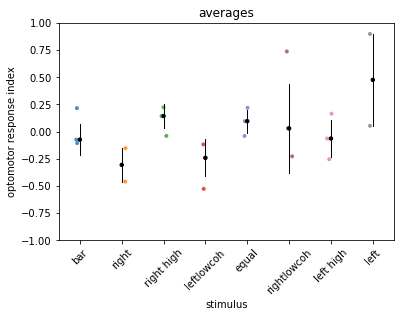

In [17]:
ax =sns.stripplot(x="stimulus", y="optomotor response index", data=averages, dodge=True, jitter=True, alpha=.8, zorder=1, size=4)
ax =sns.pointplot(x="stimulus", y="optomotor response index", ci='sd',estimator=np.median, data=averages, join=False, scale=0.5, zorder=100, color='black', errwidth=1)
plt.title('averages')
c
plt.ylabel('optomotor response index')
plt.ylim([-1, 1])

(-1.0, 1.0)

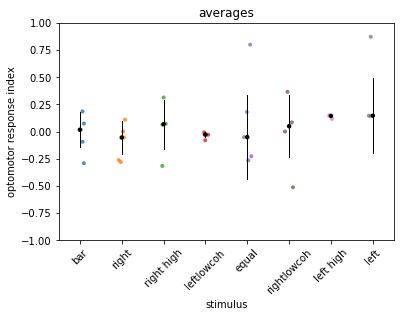

In [7]:
ax =sns.stripplot(x="stimulus", y="optomotor response index", data=averages, dodge=True, jitter=True, alpha=.8, zorder=1, size=4)
ax =sns.pointplot(x="stimulus", y="optomotor response index", ci='sd',estimator=np.median, data=averages, join=False, scale=0.5, zorder=100, color='black', errwidth=1)
plt.title('averages')
plt.xticks(rotation=45)
plt.ylabel('optomotor response index')
plt.ylim([-1, 1])

In [56]:
averages.loc[averages.stimulus =='left',:]

,stimulus,optomotor response index,distance travelled,optobarnorm,optoequalnorm,optochange
7,left,0.144956,29.385693,0.127325,0.371515,0.149043
15,left,NaN,NaN,NaN,NaN,NaN
23,left,0.872417,69.334051,0.686608,0.691904,0.518049
31,left,NaN,NaN,NaN,NaN,NaN


In [67]:
averages.loc[:, 'diff']= averages.loc[:,'optomotor response index']- averagessol.loc[:,'optomotor response index']

(-1.0, 1.0)

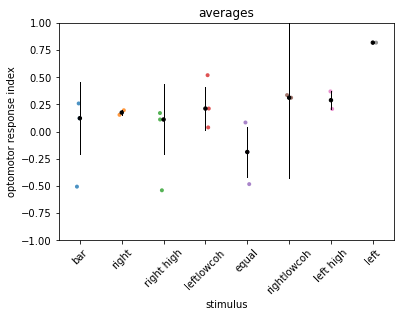

In [69]:
ax =sns.stripplot(x="stimulus", y="diff", data=averages, dodge=True, jitter=True, alpha=.8, zorder=1, size=4)
ax =sns.pointplot(x="stimulus", y="diff", ci='sd',estimator=np.median, data=averages, join=False, scale=0.5, zorder=100, color='black', errwidth=1)
plt.title('averages')
plt.xticks(rotation=45)
plt.ylabel('optomotor response index')
plt.ylim([-1, 1])  

Text(0, 0.5, 'opto-equal')

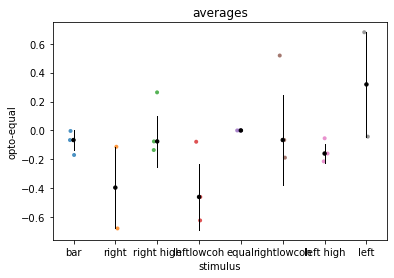

In [39]:
ax =sns.stripplot(x="stimulus", y="optoequalnorm", data=averages, dodge=True, jitter=True, alpha=.8, zorder=1, size=4)
ax =sns.pointplot(x="stimulus", y="optoequalnorm", ci='sd',estimator=np.median, data=averages, join=False, scale=0.5, zorder=100, color='black', errwidth=1)
plt.title('averages')
plt.ylabel('opto-equal')
#plt.ylim([-1, 1])

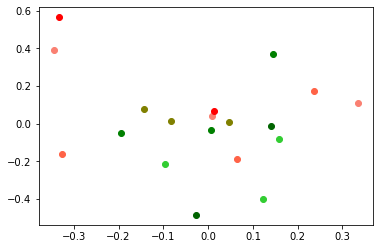

In [40]:
right = averages[averages.stimulus=='right']
plt.scatter(right.optochange-right.loc[:,'optomotor response index'], right.optochange, c='darkgreen')

righth = averages[averages.stimulus=='right high']
plt.scatter(righth.optochange-righth.loc[:,'optomotor response index'], righth.optochange, c='green')

leftl = averages[averages.stimulus=='leftlowcoh']
plt.scatter(leftl.optochange-leftl.loc[:,'optomotor response index'], leftl.optochange, c='limegreen')

equal = averages[averages.stimulus=='equal']
plt.scatter(equal.optochange-equal.loc[:,'optomotor response index'], equal.optochange, c='olive')

rightl = averages[averages.stimulus=='rightlowcoh']
plt.scatter(rightl.optochange-rightl.loc[:,'optomotor response index'], rightl.optochange, c='salmon')

lefth = averages[averages.stimulus=='left high']
plt.scatter(lefth.optochange-lefth.loc[:,'optomotor response index'], lefth.optochange, c='tomato')

left = averages[averages.stimulus=='left']
plt.scatter(left.optochange-left.loc[:,'optomotor response index'], left.optochange, c='red')



In [33]:
averagessol = averages

Text(0, 0.5, 'optochangel')

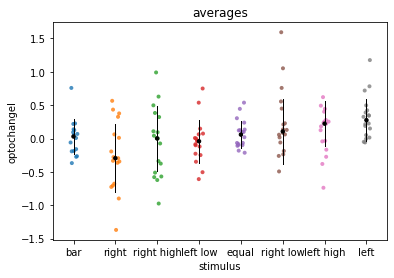

In [13]:
ax =sns.stripplot(x="stimulus", y="optochange", data=averages, dodge=True, jitter=True, alpha=.8, zorder=1, size=4)
ax =sns.pointplot(x="stimulus", y="optochange", ci='sd',estimator=np.median, data=averages, join=False, scale=0.5, zorder=100, color='black', errwidth=1)
plt.title('averages')
plt.xticks(rotation=45)
plt.ylabel('optomotor response change')
#plt.ylim([-1, 1])

(0.0, 250.0)

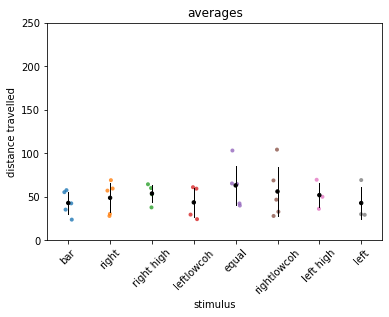

In [12]:
ax =sns.stripplot(x="stimulus", y="distance travelled", data=averages, dodge=True, jitter=True, alpha=.8, zorder=1, size=4)
ax =sns.pointplot(x="stimulus", y="distance travelled", ci='sd', data=averages, join=False, scale=0.5, zorder=100, color='black', errwidth=1)
plt.title('averages')
plt.ylabel('distance travelled')
plt.xticks(rotation=45)
plt.ylim([0, 250])
#plt.savefig('averages_80.svg')

In [4]:

def optomotor_response_idx(ev_dat):
    opt_idx =(np.nansum(abs(ev_dat.loc[ev_dat<0]))- np.nansum(abs(ev_dat.loc[ev_dat>0])))/(np.nansum(abs(ev_dat.loc[ev_dat<0]))+ np.nansum(abs(ev_dat.loc[ev_dat>0])))
    return opt_idx

In [5]:
def distance_travelled(curr_data):
        diff_dat = curr_data.loc[:, ['intergrated x position', 'intergrated y position']].diff()
        dist= np.sqrt(diff_dat.loc[:,'intergrated x position'].pow(2) + diff_dat.loc[:,'intergrated y position'].pow(2))
        distr = np.nansum(dist)
        return distr

In [239]:
def distance(curr_data):
        diff_dat = curr_data.loc[:, ['intergrated x position', 'intergrated y position']].diff(5)
        dist= np.sqrt(diff_dat.loc[:,'intergrated x position'].pow(2) + diff_dat.loc[:,'intergrated y position'].pow(2))
        dist=np.array(dist)
        return dist

In [194]:
def angle(curr_data):
        diff_dat = curr_data.loc[:, ['intergrated x position', 'intergrated y position']].diff()
        angles=np.arctan2(diff_dat.loc[:, 'intergrated y position'], diff_dat.loc[:,'intergrated x position'])
        turn = angles.diff()
        turn= np.array(turn)
        return turn